# M1 prediction diagnostics

**Question:** where does the trained water segmentation model succeed or fail?

IoU = correctly predicted water / all pixels labelled or predicted as water. False positives are dry pixels predicted as water; false negatives are labelled water missed by the model. Precision measures how often a water prediction is correct; recall measures how much labelled water is recovered.

This notebook uses the existing checkpoint and threshold, not retraining or threshold selection. It reproduces the recorded pooled metrics before displaying examples. Per-chip scores help locate failures but their average is not the published pooled IoU.

In [1]:
import os
import sys
from pathlib import Path

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT))
# Set SEN1FLOODS11_ROOT to use a different local dataset location.
root = Path(os.environ.get("SEN1FLOODS11_ROOT", str(Path.home() / ".cache/kagglehub/datasets/okimosadi/sen1floods11-handlabeled/versions/1/sen1floods11")))
assert (root / "splits/flood_test_data.csv").is_file(), f"Dataset not found: {root}"
print("Dataset:", root)


Dataset: /Users/mac/.cache/kagglehub/datasets/okimosadi/sen1floods11-handlabeled/versions/1/sen1floods11


In [2]:
import csv
import json
import hashlib
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from floodrisk.datasets.sen1floods11 import Sen1Floods11
from floodrisk.models.unet import build_unet
from floodrisk.eval.metrics import PooledIoU

torch.set_num_threads(4)
report_dir = PROJECT / "reports/m1-s1-kaggle-365653491"
out = report_dir / "diagnostics"
out.mkdir(exist_ok=True)
checkpoint = PROJECT / "best.pt"
expected = json.loads((report_dir / "evaluation.json").read_text())
assert hashlib.sha256(checkpoint.read_bytes()).hexdigest() == expected["checkpoint_sha256"]
model = build_unet(pretrained=False)
model.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True), strict=True)
model.eval()
rows = []
for split in ["test", "bolivia"]:
    ds = Sen1Floods11(root, split)
    pooled = PooledIoU()
    for i in range(len(ds)):
        x, y = ds[i]
        label = y.numpy()
        with torch.inference_mode():
            pred = (model(x.unsqueeze(0)).sigmoid()[0, 0] > 0.5).numpy()
        valid = label != -1
        truth = label == 1
        tp = int((pred & truth & valid).sum())
        fp = int((pred & ~truth & valid).sum())
        fn = int((~pred & truth & valid).sum())
        pooled.update(pred, label)
        rows.append(dict(split=split, index=i, chip=ds.items[i][0],
                         valid_pixels=int(valid.sum()), water_pixels=int((truth & valid).sum()),
                         tp=tp, fp=fp, fn=fn,
                         water_iou=tp/(tp+fp+fn) if tp+fp+fn else None))
    measured = pooled.compute()
    for key in ["iou_water", "miou"]:
        assert abs(measured[key] - expected["splits"][split][key]) < 1e-6
    print(split, measured)
with (out / "per_chip.csv").open("w") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)
print("Saved per-chip metrics; pooled metrics match the published evaluation.")


/Users/mac/Documents/Ml PROJECTS/Flood-Risk-Mapper/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


test {'iou_water': 0.6973116020508208, 'miou': 0.8236338729221924}


bolivia {'iou_water': 0.6907938699858661, 'miou': 0.8086779563529902}
Saved per-chip metrics; pooled metrics match the published evaluation.


## Inspect examples without cherry-picking

For each split, select the lowest, middle-ranked, and highest water IoU among chips with labelled water. Ties are broken by filename. These are diagnostic extremes, not a representative sample of the dataset. Grey areas are ignored labels, not correct predictions.

Radar darkness alone does not establish water. Treat possible causes such as shadows or urban structures as hypotheses until checked against suitable imagery and metadata.

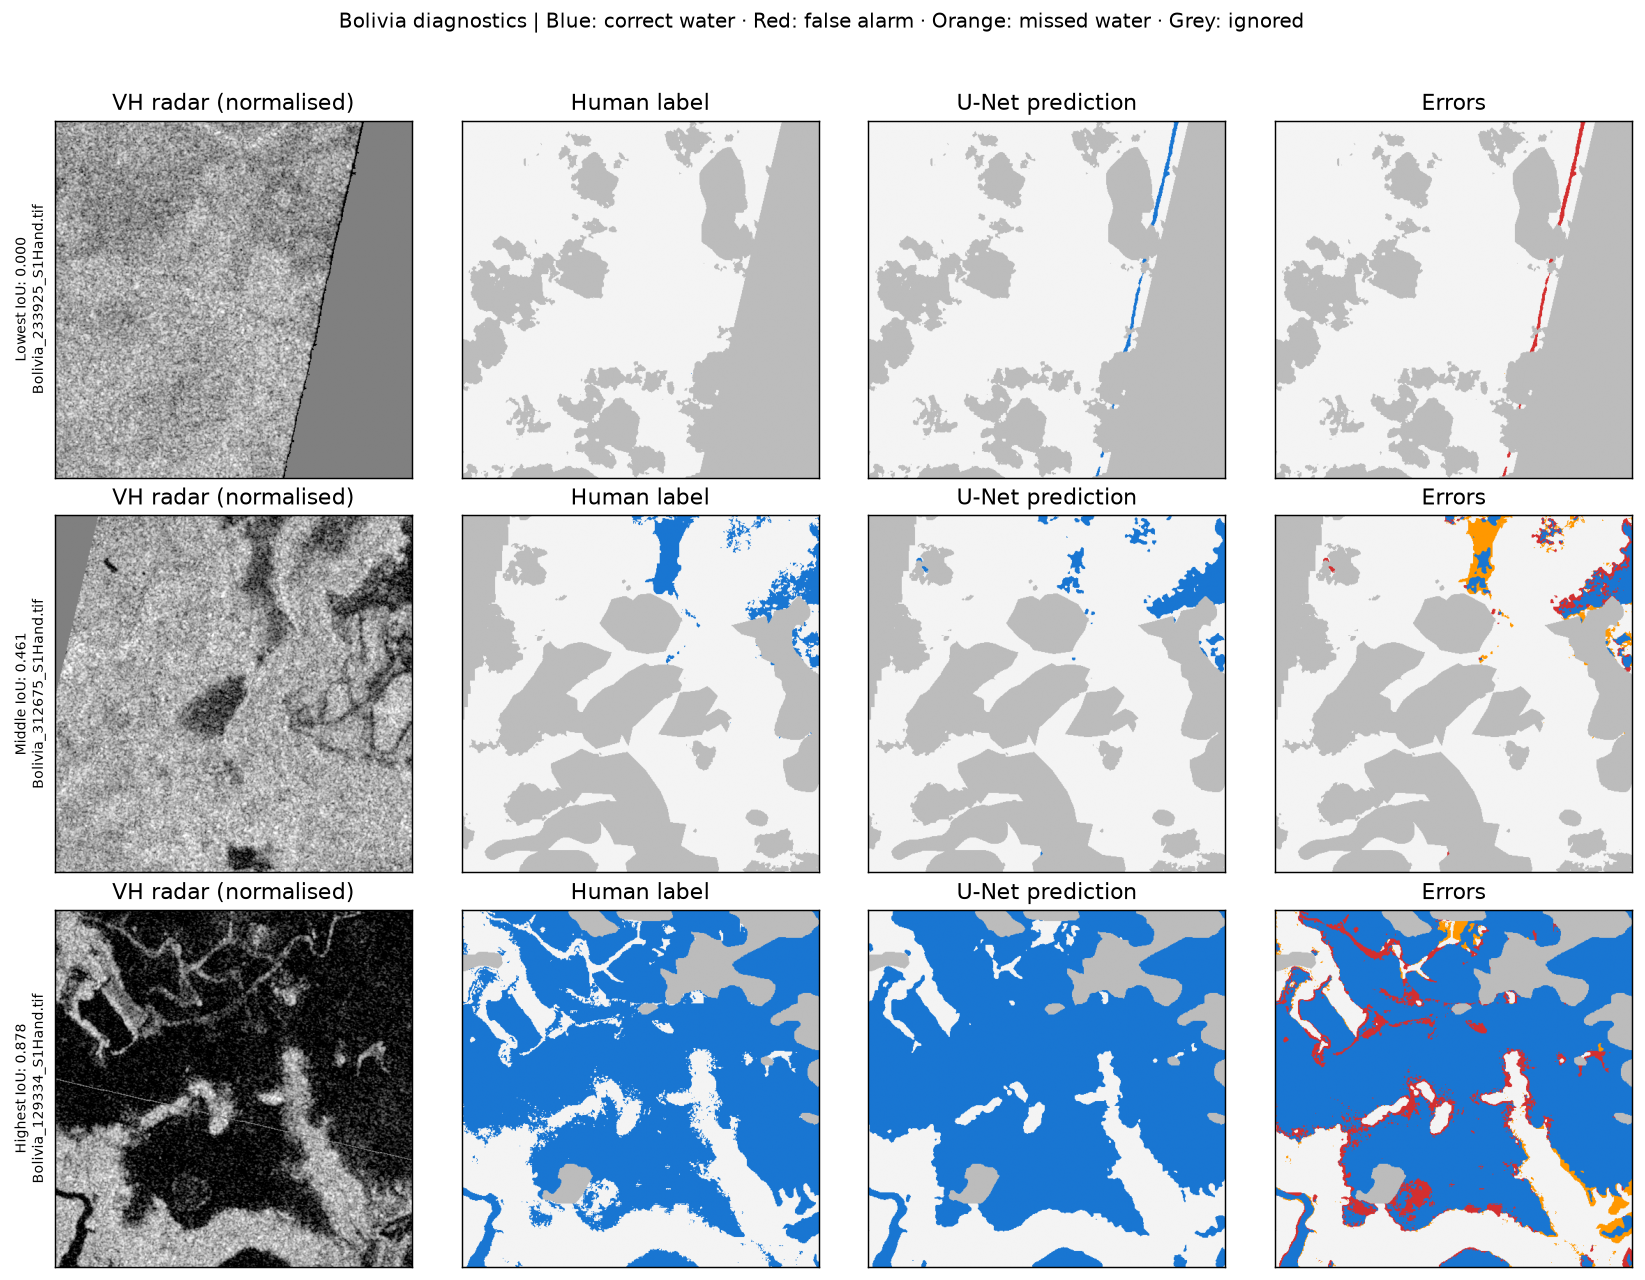

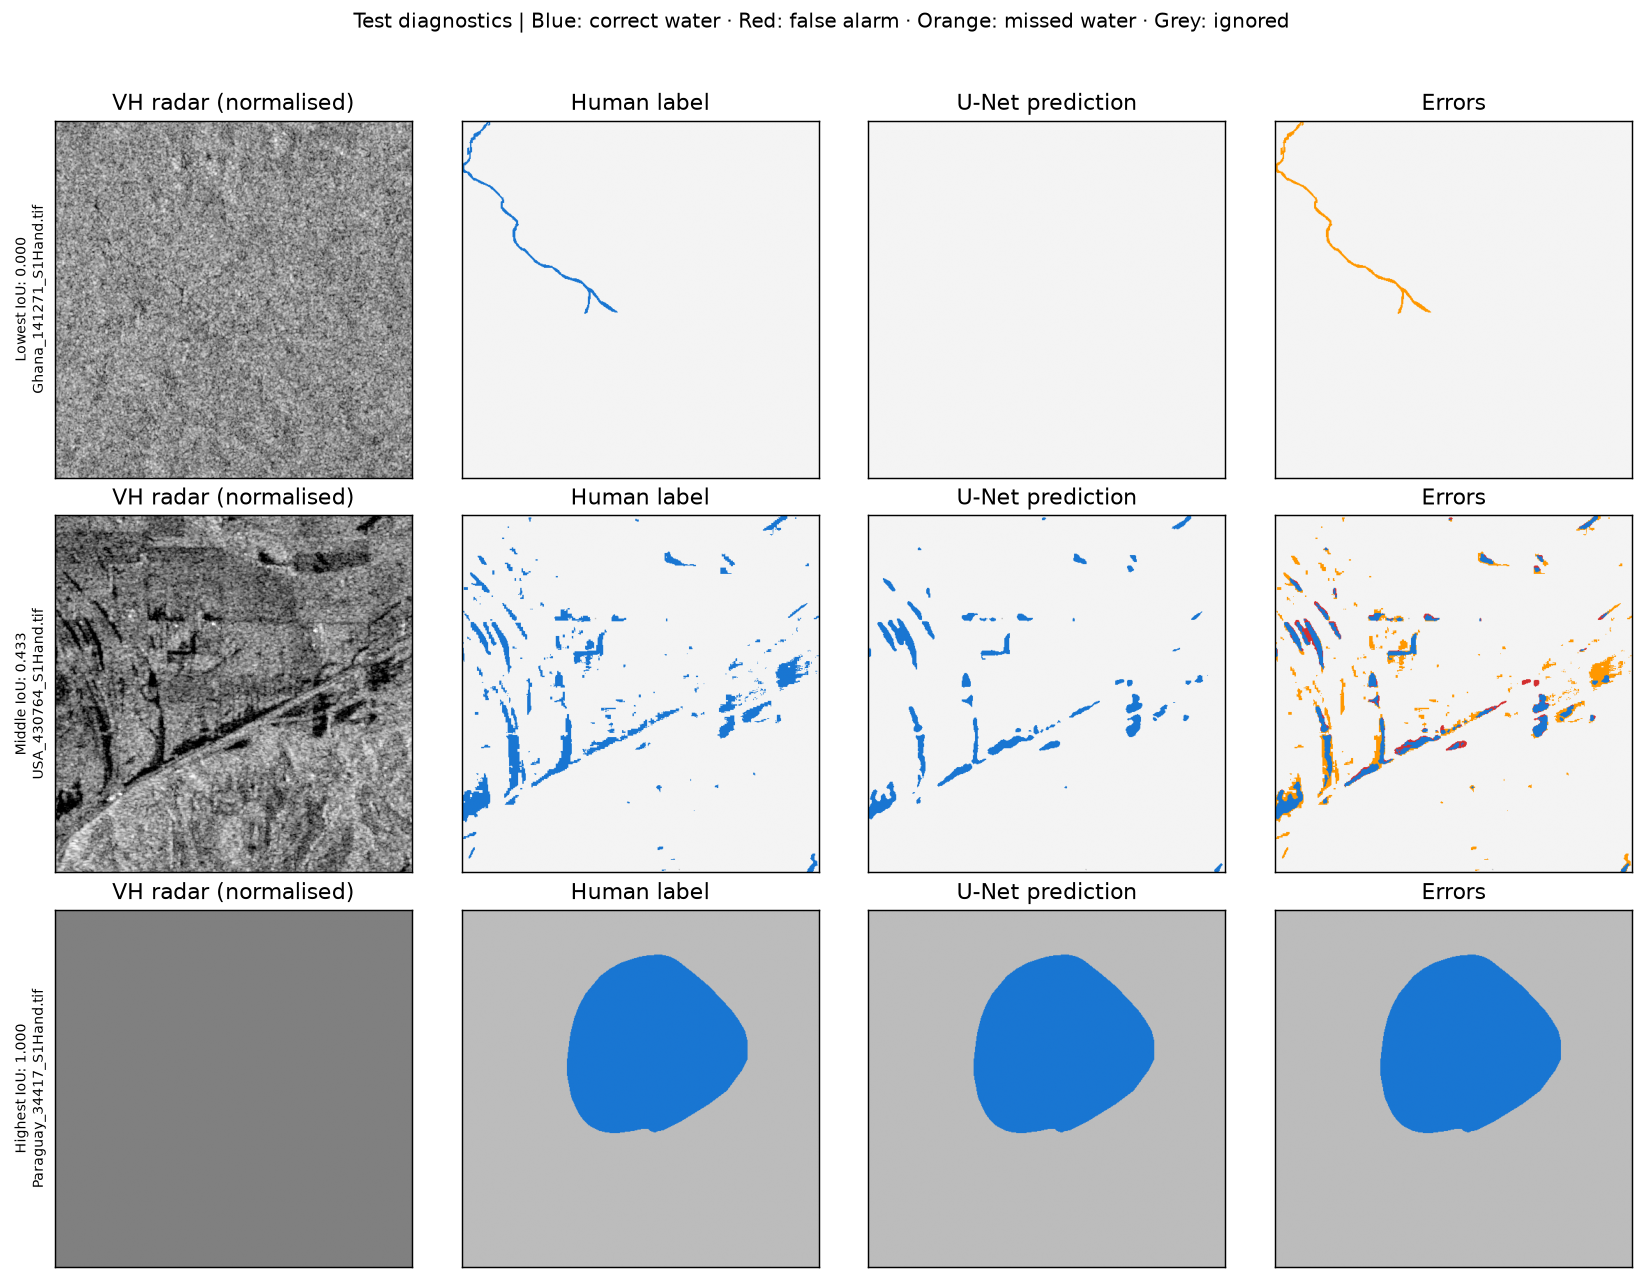

test: water precision=0.8169, recall=0.8265, false-positive pixels=475,413, missed-water pixels=445,218
bolivia: water precision=0.7563, recall=0.8886, false-positive pixels=130,257, missed-water pixels=50,666


In [3]:
for split in ["test", "bolivia"]:
    ds = Sen1Floods11(root, split)
    # Exclude chips without labelled water from example ranking; retain all in CSV.
    ranked = sorted([r for r in rows if r["split"] == split and r["water_pixels"] > 0],
                    key=lambda r: (r["water_iou"], r["chip"]))
    chosen = [ranked[0], ranked[len(ranked)//2], ranked[-1]]
    fig, axes = plt.subplots(3, 4, figsize=(13, 10))
    for row_idx, (tag, record) in enumerate(zip(["Lowest", "Middle", "Highest"], chosen)):
        x, y = ds[record["index"]]
        y = y.numpy()
        valid = y != -1
        with torch.inference_mode():
            pred = (model(x.unsqueeze(0)).sigmoid()[0, 0] > 0.5).numpy()
        errors = np.zeros_like(y)
        errors[~valid] = 4
        errors[valid & pred & (y == 1)] = 1
        errors[valid & pred & (y == 0)] = 2
        errors[valid & ~pred & (y == 1)] = 3
        masked_pred = np.where(valid, pred.astype(int), -1)
        axes[row_idx, 0].imshow(x[1], cmap="gray", vmin=-2, vmax=2)
        axes[row_idx, 1].imshow(y, cmap=ListedColormap(["#bcbcbc", "#f4f4f4", "#1976d2"]), vmin=-1, vmax=1)
        axes[row_idx, 2].imshow(masked_pred, cmap=ListedColormap(["#bcbcbc", "#f4f4f4", "#1976d2"]), vmin=-1, vmax=1)
        axes[row_idx, 3].imshow(errors, cmap=ListedColormap(["#f4f4f4", "#1976d2", "#d32f2f", "#ff9800", "#bcbcbc"]), vmin=0, vmax=4)
        for ax, title in zip(axes[row_idx], ["VH radar (normalised)", "Human label", "U-Net prediction", "Errors"]):
            ax.set_title(title)
            ax.set_xticks([]); ax.set_yticks([])
        axes[row_idx, 0].set_ylabel(f"{tag} IoU: {record['water_iou']:.3f}\n{record['chip']}", fontsize=8)
    fig.suptitle(f"{split.title()} diagnostics | Blue: correct water · Red: false alarm · Orange: missed water · Grey: ignored", fontsize=11)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(out / f"{split}_examples.png", dpi=130, bbox_inches="tight")
    from IPython.display import display, Image
    display(Image(filename=str(out / f"{split}_examples.png")))
    plt.close(fig)

for split in ["test", "bolivia"]:
    selected = [r for r in rows if r["split"] == split]
    tp, fp, fn = (sum(r[k] for r in selected) for k in ["tp", "fp", "fn"])
    print(f"{split}: water precision={tp/(tp+fp):.4f}, recall={tp/(tp+fn):.4f}, false-positive pixels={fp:,}, missed-water pixels={fn:,}")


## How to explain this work

“I trained a radar-based water segmentation model and evaluated it on held-out data. I then mapped false positives and false negatives to see what the aggregate score hides. The model improved on the test baseline but not on the Bolivia baseline. That motivates further validation of geographic robustness, rather than claiming it works equally well everywhere.”

Choose future model changes with training/validation data. Repeatedly tuning on these held-out examples would weaken the evaluation. Nigeria-specific performance still requires an independent labelled evaluation set.

## Observed caveats

Bolivia precision is **0.7563**, recall **0.8886**; test precision is **0.8169**, recall **0.8265**. Bolivia has more false-positive than missed-water pixels.

The highest-ranked test chip, `Paraguay_34417`, has all-NaN input and only water in its valid labels. Its perfect IoU is not evidence of meaningful radar interpretation. The lowest Bolivia chip, `Bolivia_233925`, has just one labelled water pixel. These examples show why per-chip rankings need input-quality and label-coverage context. See the diagnostics report and `input_quality.json` for the audit. Published benchmark metrics remain unchanged; any alternate missing-input policy must be explicit and applied consistently to all models.